# NewsCLIPpings EDA
These are annotation records, not validated image-caption pairs. `falsified` is an image-caption mismatch label, not a fake-news label.

,final_split,normalized_label,annotations
0,test,matched,62084
1,test,mismatched,62084
2,train,matched,591450
3,train,mismatched,591450
4,validate,matched,61746
5,validate,mismatched,61746


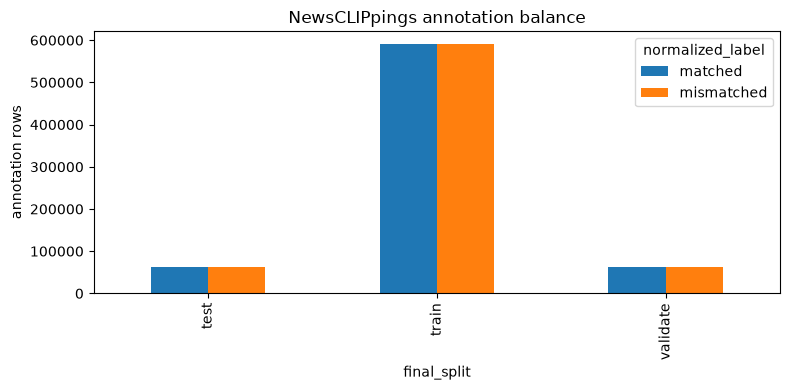

Verified local NewsCLIPpings pairs: 0


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
root = Path('../data/research_dataset')
m = pd.read_parquet(root / 'manifests/unified_manifest.parquet')
n = m.query("source_dataset == 'NewsCLIPpings'")
display(n.groupby(['final_split', 'normalized_label']).size().rename('annotations').reset_index())
n.groupby(['final_split', 'normalized_label']).size().unstack(fill_value=0).plot(kind='bar', figsize=(8,4), title='NewsCLIPpings annotation balance')
plt.ylabel('annotation rows'); plt.tight_layout(); plt.show()
assert n.image_path.isna().all(), 'Do not treat unresolved rows as pairs'
print('Verified local NewsCLIPpings pairs:', (n.download_status == 'verified_reused_or_processed').sum())